## Part 3: Contest

Cats vs Dogs binary classification.  **No pretrained weights are used** — every
model is trained from random initialisation on the provided training split only.

Approach:
* **SE-ResNet18** (Residual network with Squeeze-and-Excitation blocks and
  stochastic depth), ~11.3M parameters, built from scratch in PyTorch.
* **Progressive resizing**: 128 px -> 176 px -> 224 px -> 288 px during training
  (cheap early epochs, high-resolution fine-tuning at the end).
* Strong regularisation: RandAugment, RandomErasing, mixup/cutmix,
  label smoothing, weight decay, stochastic depth, cosine LR with warmup.
* Best-checkpoint selection on the validation split.
* **Ensemble of 4 models** (ResNet-18 x2, a wider ResNet-18 and a ResNet-34;
  different seeds), short fine-tune on `train + val`,
  and **multi-scale (224/256/288 px) + horizontal-flip TTA** with weights and
  threshold tuned on the validation split.

In [1]:
import copy
import itertools
import math
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, ConcatDataset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

RESUME = True  # reuse contest_*.pt checkpoints if a previous run was interrupted
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

Using device: cuda
NVIDIA GeForce RTX 4060


In [2]:
base_dir = Path('workshops/7/Cats_and_Dogs')
train_dir = base_dir / 'train'
val_dir = base_dir / 'val'
test_dir = base_dir / 'test'

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
num_workers = 6 if device.type == 'cuda' else 0

# no mixup/cutmix during the last COOLDOWN epochs (faster final convergence)
COOLDOWN = 10


def build_transforms(size):
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(size, scale=(0.5, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandAugment(num_ops=2, magnitude=9),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
        transforms.RandomErasing(p=0.15),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize(int(size * 1.14)),
        transforms.CenterCrop(size),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf


# Three independently initialised models (different seeds) form the ensemble.
MODEL_SPECS = [
    # 80 epochs each: 10 @128, 15 @176, 45 @224, 10 @288 (progressive resizing)
    {'name': 'se_r18_a', 'seed': 42,   'widths': (64, 128, 256, 512), 'blocks': (2, 2, 2, 2),
     'drop_path': 0.10, 'bs': 48, 'lr': 0.05, 'wd': 5e-4,
     'sizes': [(128, 10), (176, 15), (224, 45), (288, 10)]},
    {'name': 'se_r18_b', 'seed': 7,    'widths': (64, 128, 256, 512), 'blocks': (2, 2, 2, 2),
     'drop_path': 0.15, 'bs': 48, 'lr': 0.05, 'wd': 5e-4,
     'sizes': [(128, 10), (176, 15), (224, 45), (288, 10)]},
    {'name': 'se_r18_w', 'seed': 2024, 'widths': (80, 160, 320, 640), 'blocks': (2, 2, 2, 2),
     'drop_path': 0.10, 'bs': 48, 'lr': 0.05, 'wd': 5e-4,
     'sizes': [(128, 10), (176, 15), (224, 45), (288, 10)]},
    {'name': 'se_r34',   'seed': 123,  'widths': (64, 128, 256, 512), 'blocks': (3, 4, 6, 3),
     'drop_path': 0.10, 'bs': 48, 'lr': 0.05, 'wd': 5e-4,
     'sizes': [(128, 10), (176, 15), (224, 45), (288, 10)]},
]
print(f"Ensemble: {[m['name'] for m in MODEL_SPECS]}")

Ensemble: ['se_r18_a', 'se_r18_b', 'se_r18_w', 'se_r34']


In [3]:
# ------------------------- model (trained from scratch) -------------------------
class SE(nn.Module):
    """Squeeze-and-Excitation block."""

    def __init__(self, ch, r=16):
        super().__init__()
        hidden = max(ch // r, 8)
        self.fc1 = nn.Conv2d(ch, hidden, 1)
        self.fc2 = nn.Conv2d(hidden, ch, 1)

    def forward(self, x):
        s = F.adaptive_avg_pool2d(x, 1)
        s = torch.sigmoid(self.fc2(F.relu(self.fc1(s), inplace=True)))
        return x * s


class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, drop_path=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.se = SE(out_ch)
        self.drop_path = drop_path
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.se(self.bn2(self.conv2(out)))
        if self.drop_path > 0 and self.training:
            keep = 1.0 - self.drop_path
            mask = torch.rand(out.size(0), 1, 1, 1, device=out.device) < keep
            out = out * mask / keep
        return F.relu(out + self.shortcut(x), inplace=True)


class SEResNet18(nn.Module):
    """ResNet-18 with SE blocks and stochastic depth, from random init."""

    def __init__(self, num_classes=2, widths=(64, 128, 256, 512),
                 blocks=(2, 2, 2, 2), drop_path=0.1, dropout=0.2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, 2, 3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1),
        )
        layers = []
        in_ch = 64
        total = sum(blocks)
        idx = 0
        for stage, (w, n) in enumerate(zip(widths, blocks)):
            for b in range(n):
                stride = 2 if (b == 0 and stage > 0) else 1
                dp = drop_path * idx / max(total - 1, 1)
                layers.append(BasicBlock(in_ch, w, stride, dp))
                in_ch = w
                idx += 1
        self.stages = nn.Sequential(*layers)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(in_ch, num_classes),
        )
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        nn.init.zeros_(self.head[3].bias)

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


print(f"SE-ResNet18 parameters: {sum(p.numel() for p in SEResNet18().parameters()) / 1e6:.1f}M")

SE-ResNet18 parameters: 11.3M


In [4]:
def mixup_cutmix(x, y, num_classes=2, prob=0.5):
    """Return mixed inputs and soft targets (mixup or cutmix)."""
    y1 = F.one_hot(y, num_classes).float()
    if random.random() > prob:
        return x, y1
    idx = torch.randperm(x.size(0), device=x.device)
    if random.random() < 0.5:
        lam = float(np.random.beta(0.2, 0.2))
        x = lam * x + (1 - lam) * x[idx]
        y = lam * y1 + (1 - lam) * y1[idx]
    else:
        lam = float(np.random.beta(1.0, 1.0))
        h, w = x.size(2), x.size(3)
        rh, rw = int(h * math.sqrt(1 - lam)), int(w * math.sqrt(1 - lam))
        cy, cx = np.random.randint(h), np.random.randint(w)
        y0, y1_ = max(cy - rh // 2, 0), min(cy + rh // 2, h)
        x0, x1_ = max(cx - rw // 2, 0), min(cx + rw // 2, w)
        x[:, :, y0:y1_, x0:x1_] = x[idx, :, y0:y1_, x0:x1_]
        lam = 1 - ((y1_ - y0) * (x1_ - x0) / (h * w))
        y = lam * y1 + (1 - lam) * y1[idx]
    return x, y


@torch.no_grad()
def evaluate(model, loader, tta=True):
    model.eval()
    correct = total = 0
    probs = []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=device.type == 'cuda'):
            p = F.softmax(model(x).float(), dim=1)
            if tta:
                p = p + F.softmax(model(torch.flip(x, dims=[3])).float(), dim=1)
        p = (p / 2 if tta else p).cpu()
        probs.append(p)
        correct += (p.argmax(1) == y).sum().item()
        total += y.size(0)
    return 100.0 * correct / total, torch.cat(probs)

In [5]:
def train_one(spec):
    """Train a single from-scratch model with progressive resizing."""
    torch.manual_seed(spec['seed'])
    np.random.seed(spec['seed'])
    random.seed(spec['seed'])

    train_sets = {}
    for size, _ in spec['sizes']:
        tr_tf, _ = build_transforms(size)
        train_sets[size] = datasets.ImageFolder(train_dir, transform=tr_tf)

    final_size = spec['sizes'][-1][0]
    _, ev_tf = build_transforms(final_size)
    val_ds = datasets.ImageFolder(val_dir, transform=ev_tf)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=num_workers,
                            pin_memory=True, persistent_workers=num_workers > 0)

    model = SEResNet18(widths=spec['widths'], blocks=spec['blocks'],
                       drop_path=spec['drop_path']).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.SGD(model.parameters(), lr=spec['lr'], momentum=0.9,
                          nesterov=True, weight_decay=spec['wd'])
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    steps_per_epoch = {s: len(train_sets[s]) // spec['bs'] for s, _ in spec['sizes']}
    total_steps = sum(steps_per_epoch[s] * e for s, e in spec['sizes'])
    warmup_steps = 3 * steps_per_epoch[spec['sizes'][0][0]]

    def lr_at(step):
        if step < warmup_steps:
            return step / max(warmup_steps, 1)
        p = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
        return 0.5 * (1 + math.cos(math.pi * p))

    history = {'loss': [], 'val_acc': []}
    best_acc, best_state = 0.0, None
    step = epoch = 0
    total_epochs = sum(e for _, e in spec['sizes'])
    for size, n_ep in spec['sizes']:
        loader = DataLoader(train_sets[size], batch_size=spec['bs'], shuffle=True,
                            num_workers=num_workers, pin_memory=True, drop_last=True,
                            persistent_workers=num_workers > 0)
        for _ in range(n_ep):
            epoch += 1
            model.train()
            t0 = time.time()
            running = 0.0
            for x, y in loader:
                lr = spec['lr'] * lr_at(step)
                for g in optimizer.param_groups:
                    g['lr'] = lr
                x = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True)
                if epoch > total_epochs - COOLDOWN:
                    yt = F.one_hot(y, 2).float()
                else:
                    x, yt = mixup_cutmix(x, y)
                optimizer.zero_grad(set_to_none=True)
                with torch.amp.autocast('cuda', enabled=device.type == 'cuda'):
                    loss = criterion(model(x), yt)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                step += 1
                running += loss.item()

            acc, _ = evaluate(model, val_loader, tta=False)

            history['loss'].append(running / steps_per_epoch[size])
            history['val_acc'].append(acc)
            if acc > best_acc:
                best_acc = acc
                best_state = copy.deepcopy(model.state_dict())
            print(f"  [{spec['name']}] epoch {epoch}/{total_epochs} @{size}px loss {running/steps_per_epoch[size]:.4f} "
                  f"val {acc:.2f}% lr {lr:.2e} {time.time()-t0:.0f}s", flush=True)

    model.load_state_dict(best_state)
    print(f"  [{spec['name']}] BEST val {best_acc:.2f}%", flush=True)
    del optimizer, scaler, loader
    torch.cuda.empty_cache()
    return best_state, history, best_acc

In [6]:
# Train the ensemble members (all from random initialisation).
trained = {}
for spec in MODEL_SPECS:
    print(f"=== {spec['name']} (seed {spec['seed']}) ===", flush=True)
    ckpt = Path(f"contest_{spec['name']}.pt")
    if RESUME and ckpt.exists():
        # continue an interrupted run: reload the checkpoint and report its val accuracy
        state = torch.load(ckpt, weights_only=True)
        model = SEResNet18(widths=spec['widths'], blocks=spec['blocks'],
                           drop_path=spec['drop_path']).to(device)
        model.load_state_dict(state)
        _, ev_tf = build_transforms(spec['sizes'][-1][0])
        vl = DataLoader(datasets.ImageFolder(val_dir, transform=ev_tf), batch_size=64,
                        shuffle=False, num_workers=num_workers)
        best_acc, _ = evaluate(model, vl, tta=False)
        del model, vl
        torch.cuda.empty_cache()
        hist = {'loss': [], 'val_acc': []}
        print(f"  loaded {ckpt}: val {best_acc:.2f}%", flush=True)
    else:
        state, hist, best_acc = train_one(spec)
    trained[spec['name']] = {'spec': spec, 'state': state,
                             'history': hist, 'best_val': best_acc}
    torch.save(state, f"contest_{spec['name']}.pt")

print("\nIndividual validation accuracy:")
for name, d in trained.items():
    print(f"  {name:20s} {d['best_val']:.2f}%")

=== se_r18_a (seed 42) ===


  [se_r18_a] epoch 1/80 @128px loss 0.7026 val 59.40% lr 1.66e-02 55s


  [se_r18_a] epoch 2/80 @128px loss 0.7160 val 61.04% lr 3.33e-02 12s


  [se_r18_a] epoch 3/80 @128px loss 0.6783 val 56.91% lr 5.00e-02 12s


  [se_r18_a] epoch 4/80 @128px loss 0.6513 val 54.46% lr 5.00e-02 12s


  [se_r18_a] epoch 5/80 @128px loss 0.6295 val 55.54% lr 4.99e-02 12s


... (319 outputs left out)

  [se_r34] epoch 79/80 @288px loss 0.2235 val 98.92% lr 2.09e-05 67s


  [se_r34] epoch 80/80 @288px loss 0.2239 val 98.92% lr 1.20e-10 67s


  [se_r34] BEST val 99.04%



Individual validation accuracy:
  se_r18_a             98.84%
  se_r18_b             98.67%
  se_r18_w             99.08%
  se_r34               99.04%


In [7]:
# Short fine-tune on train + val (all labelled data) before the final prediction.
FINETUNE_EPOCHS = 3
for name, d in trained.items():
    spec = d['spec']
    size = spec['sizes'][-1][0]
    tr_tf, _ = build_transforms(size)
    full_ds = ConcatDataset([
        datasets.ImageFolder(train_dir, transform=tr_tf),
        datasets.ImageFolder(val_dir, transform=tr_tf),
    ])
    loader = DataLoader(full_ds, batch_size=spec['bs'], shuffle=True, num_workers=num_workers,
                        pin_memory=True, drop_last=True, persistent_workers=num_workers > 0)

    model = SEResNet18(widths=spec['widths'], blocks=spec['blocks'],
                       drop_path=spec['drop_path']).to(device)
    model.load_state_dict(d['state'])
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.SGD(model.parameters(), lr=2e-3, momentum=0.9, nesterov=True,
                          weight_decay=spec['wd'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINETUNE_EPOCHS * len(loader))
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')

    for epoch in range(FINETUNE_EPOCHS):
        model.train()
        running = 0.0
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            x, yt = mixup_cutmix(x, y)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=device.type == 'cuda'):
                loss = criterion(model(x), yt)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
        print(f"  [{name}] full-data epoch {epoch + 1}/{FINETUNE_EPOCHS} "
              f"loss {running / len(loader):.4f}", flush=True)

    d['final_state'] = copy.deepcopy(model.state_dict())
    torch.save(d['final_state'], f"contest_{name}_full.pt")
    del model, optimizer, scaler
    torch.cuda.empty_cache()

  [se_r18_a] full-data epoch 1/3 loss 0.3173


  [se_r18_a] full-data epoch 2/3 loss 0.3218


  [se_r18_a] full-data epoch 3/3 loss 0.3129


  [se_r18_b] full-data epoch 1/3 loss 0.3236


  [se_r18_b] full-data epoch 2/3 loss 0.3174


  [se_r18_b] full-data epoch 3/3 loss 0.3173


... (2 outputs left out)

  [se_r18_w] full-data epoch 3/3 loss 0.3106


  [se_r34] full-data epoch 1/3 loss 0.3110


  [se_r34] full-data epoch 2/3 loss 0.3049


  [se_r34] full-data epoch 3/3 loss 0.3038


In [8]:
# Multi-scale + horizontal-flip TTA.
@torch.no_grad()
def tta_probs(model, folder, scales, bs=64):
    model.eval()
    probs = None
    for size in scales:
        tf = transforms.Compose([
            transforms.Resize(int(size * 1.14)),
            transforms.CenterCrop(size),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
        loader = DataLoader(datasets.ImageFolder(folder, transform=tf), batch_size=bs,
                            shuffle=False, num_workers=num_workers, pin_memory=True)
        acc = torch.zeros(len(loader.dataset), 2)
        start = 0
        for x, _ in loader:
            x = x.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=device.type == 'cuda'):
                p = F.softmax(model(x).float(), dim=1)
                p = p + F.softmax(model(torch.flip(x, dims=[3])).float(), dim=1)
            acc[start:start + x.size(0)] = (p / 2).cpu()
            start += x.size(0)
        probs = acc if probs is None else probs + acc
    return probs / len(scales)


def model_probs(name, state_key, folder):
    spec = trained[name]['spec']
    size = spec['sizes'][-1][0]
    model = SEResNet18(widths=spec['widths'], blocks=spec['blocks'],
                       drop_path=spec['drop_path']).to(device)
    model.load_state_dict(trained[name][state_key])
    # 224 / 256 / 288: the resolutions the model trained on (do not extrapolate)
    p = tta_probs(model, folder, [int(size * 0.78), int(size * 0.89), size])
    del model
    torch.cuda.empty_cache()
    return p


names = list(trained.keys())
val_targets = datasets.ImageFolder(val_dir).targets
val_probs = {n: model_probs(n, 'state', val_dir) for n in names}
for n in names:
    print(f"  {n:20s} val TTA "
          f"{100.0 * (val_probs[n].argmax(1) == torch.tensor(val_targets)).float().mean().item():.2f}%")

  se_r18_a             val TTA 99.08%
  se_r18_b             val TTA 98.84%
  se_r18_w             val TTA 99.12%
  se_r34               val TTA 99.00%


In [9]:
# Ensemble weights + decision threshold, selected on validation (works for any N models).
names = list(trained.keys())
dog_probs = torch.stack([val_probs[n][:, 1] for n in names], dim=1)   # (N_val, N_models)
val_targets_t = torch.tensor(val_targets)

grid = np.arange(0, 1.001, 0.1)
thresholds = np.arange(0.30, 0.71, 0.02)
best = {'acc': -1, 'w': None, 'thr': 0.5}
for combo in itertools.product(grid, repeat=len(names) - 1):
    last = 1 - sum(combo)
    if last < -1e-9:
        continue
    w = torch.tensor(list(combo) + [last], dtype=torch.float32)
    p_dog = dog_probs @ w
    for thr in thresholds:
        pred = (p_dog >= thr).long()
        acc = 100.0 * (pred == val_targets_t).float().mean().item()
        if acc > best['acc']:
            best = {'acc': acc, 'w': [float(x) for x in w], 'thr': float(thr)}

print(f"Best validation ensemble: {best['acc']:.2f}%  weights={best['w']}  threshold={best['thr']:.2f}")
ensemble_weights = dict(zip(names, best['w']))
threshold = best['thr']


Best validation ensemble: 99.36%  weights=[0.30000001192092896, 0.10000000149011612, 0.10000000149011612, 0.5]  threshold=0.56


In [10]:
# Final test prediction with the full-data models.
test_probs_each = {n: model_probs(n, 'final_state', test_dir) for n in names}
test_targets = torch.tensor(datasets.ImageFolder(test_dir).targets)
test_probs = sum(ensemble_weights[n] * test_probs_each[n] for n in names)
test_pred = (test_probs[:, 1] >= threshold).long()
test_accuracy = 100.0 * (test_pred == test_targets).float().mean().item()

print("Per-model test accuracy (TTA):")
for n in names:
    acc = 100.0 * (test_probs_each[n].argmax(1) == test_targets).float().mean().item()
    print(f"  {n:20s} {acc:.2f}%")
print(f"\nENSEMBLE test accuracy: {test_accuracy:.2f}%")

Per-model test accuracy (TTA):
  se_r18_a             98.40%
  se_r18_b             98.36%
  se_r18_w             98.56%
  se_r34               98.40%

ENSEMBLE test accuracy: 98.56%


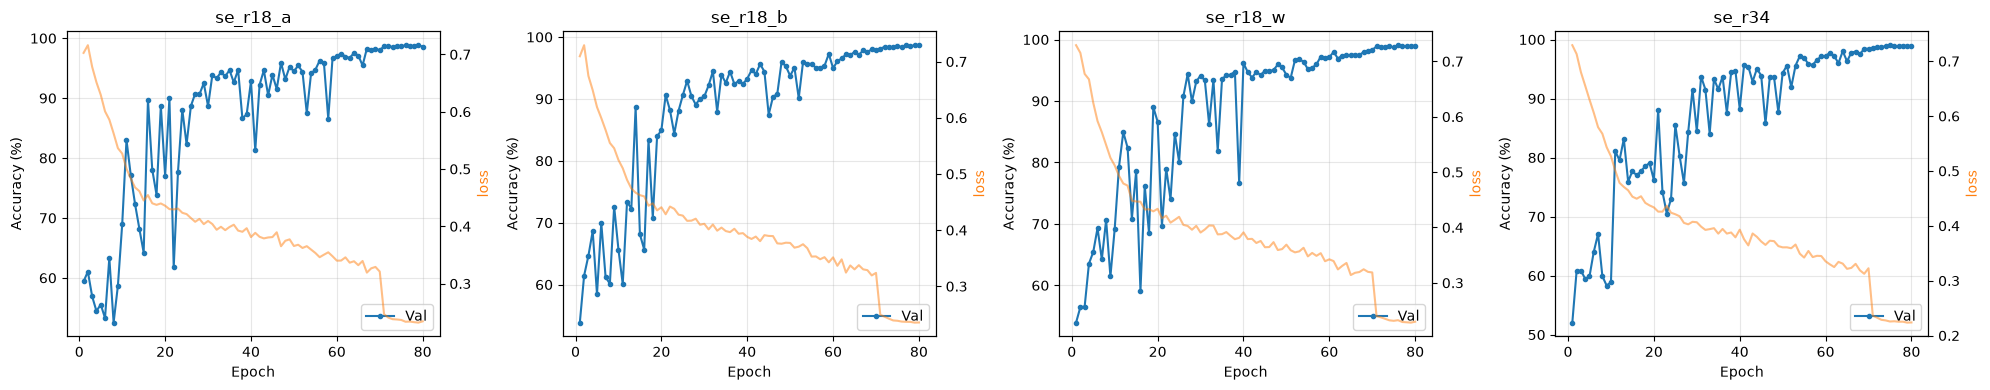

In [11]:
n_models = len(trained)
fig, axes = plt.subplots(1, n_models, figsize=(5 * n_models, 4), squeeze=False)
for ax, (name, d) in zip(axes[0], trained.items()):
    epochs = range(1, len(d['history']['val_acc']) + 1)
    ax.plot(epochs, d['history']['val_acc'], marker='o', ms=3, label='Val')
    if d['history']['loss']:
        ax2 = ax.twinx()
        ax2.plot(epochs, d['history']['loss'], color='tab:orange', alpha=0.5)
        ax2.set_ylabel('loss', color='tab:orange')
    ax.set_title(name)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy (%)')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [12]:
summary_df = pd.DataFrame([{
    'Model': 'SE-ResNet18 / -34 x4 ensemble, from scratch (TTA)',
    'Best Val Accuracy (%)': round(best['acc'], 2),
    'Test Accuracy (%)': round(test_accuracy, 2),
}]).set_index('Model')
summary_df

,Best Val Accuracy (%),Test Accuracy (%)
Model,,
"SE-ResNet18 / -34 x4 ensemble, from scratch (TTA)",99.36,98.56
